### Task 1: Smart Campus Exam Scheduler Using Backtracking

In [8]:
courses = ["AI", "DB", "CN", "SE", "ML", "DS"]

slots = ["Mon-9", "Mon-11", "Tue-9", "Tue-11"]

domains = {course: slots[:] for course in courses}

conflicts = [
    ("AI", "DB"), ("AI", "CN"), ("AI", "DS"),
    ("DB", "SE"), ("DB", "ML"), ("CN", "ML"),
    ("SE", "DS"), ("ML", "DS"),
]

neighbors = {course: [] for course in courses}

for c1, c2 in conflicts:
    neighbors[c1].append(c2)
    neighbors[c2].append(c1)

print("Constraint graph:")
for course in courses:
    print(course, "->", neighbors[course])


def is_consistent(course, slot, assignment):
    return all(assignment.get(n) != slot for n in neighbors[course])


def backtrack(assignment):
    if len(assignment) == len(courses):
        return assignment

    course = next(c for c in courses if c not in assignment)

    for slot in domains[course]:
        attempts[0] += 1

        if is_consistent(course, slot, assignment):
            assignment[course] = slot

            if backtrack(assignment):
                return assignment

            del assignment[course]

    return None


def show(solution):
    if solution is None:
        print("No valid timetable exists.")
        return
    print(f"{'Course':<8}Assigned time slot")
    for course in courses:
        print(f"{course:<8}{solution[course]}")


attempts = [0]
solution = backtrack({})

show(solution)
print("Candidate assignments attempted:", attempts[0])

Constraint graph:
AI -> ['DB', 'CN', 'DS']
DB -> ['AI', 'SE', 'ML']
CN -> ['AI', 'ML']
SE -> ['DB', 'DS']
ML -> ['DB', 'CN', 'DS']
DS -> ['AI', 'SE', 'ML']
Course  Assigned time slot
AI      Mon-9
DB      Mon-11
CN      Mon-11
SE      Mon-9
ML      Mon-9
DS      Mon-11
Candidate assignments attempted: 9


### Task 2: Intelligent Course Scheduling Using MRV, Degree Heuristic, and LCV

In [9]:
def legal(course, assignment):
    return [s for s in domains[course] if is_consistent(course, s, assignment)]


def select_variable(assignment):
    unassigned = [c for c in courses if c not in assignment]
    return min(
        unassigned,
        key=lambda c: (
            len(legal(c, assignment)),
            -sum(n not in assignment for n in neighbors[c]),
        ),
    )


def order_values(course, assignment):
    def eliminated(slot):
        return sum(
            slot in legal(n, assignment)
            for n in neighbors[course]
            if n not in assignment
        )

    return sorted(legal(course, assignment), key=eliminated)


def backtrack(assignment, use_heuristics, stats):
    if len(assignment) == len(courses):
        return assignment

    if use_heuristics:
        course = select_variable(assignment)
        values = order_values(course, assignment)
    else:
        course = next(c for c in courses if c not in assignment)
        values = domains[course]

    for slot in values:
        stats["attempts"] += 1

        if is_consistent(course, slot, assignment):
            assignment[course] = slot

            if backtrack(assignment, use_heuristics, stats):
                return assignment

            del assignment[course]

    return None


for name, use_heuristics in (("Basic backtracking", False), ("MRV + Degree + LCV", True)):
    stats = {"attempts": 0}
    solution = backtrack({}, use_heuristics, stats)
    print(name)
    show(solution)
    print("Candidate assignments attempted:", stats["attempts"])
    print()

Basic backtracking
Course  Assigned time slot
AI      Mon-9
DB      Mon-11
CN      Mon-11
SE      Mon-9
ML      Mon-9
DS      Mon-11
Candidate assignments attempted: 9

MRV + Degree + LCV
Course  Assigned time slot
AI      Mon-9
DB      Mon-11
CN      Mon-11
SE      Mon-9
ML      Mon-9
DS      Mon-11
Candidate assignments attempted: 6



**Analysis**

- **MRV:** It picks the course with the fewest legal slots, so a course with zero legal slots is found immediately, instead of only when the fixed order reaches it.
- **Degree heuristic:** On an MRV tie it picks the course with the most unassigned neighbours, which is the one most likely to cause conflicts later, so those conflicts show up early.
- **LCV:** It tries first the slot that removes the fewest options from neighbouring courses, which leaves them the most room.
- **Result:** Yes. Basic backtracking made 9 attempts and MRV + Degree + LCV made 6, with the same valid timetable. This is a small problem, and the saving comes from avoiding the failed attempts at AI/DB/CN. It is not guaranteed on other CSPs.

### Task 3: Smart Scheduler with Forward Checking

In [10]:
initial_domains = {course: slots[:] for course in courses}


def backtrack_fc(assignment, domains, stats):
    if len(assignment) == len(courses):
        return assignment

    course = next(c for c in courses if c not in assignment)

    for slot in domains[course][:]:
        stats["attempts"] += 1

        if not is_consistent(course, slot, assignment):
            continue

        saved = {c: d[:] for c, d in domains.items()}

        assignment[course] = slot
        domains[course] = [slot]

        failed = False

        for n in neighbors[course]:
            if n not in assignment and slot in domains[n]:
                domains[n].remove(slot)
                stats["removed"] += 1
                print(f"[debug] {course}={slot}: removed {slot} from {n}, {n} domain now {domains[n]}")

                if not domains[n]:
                    failed = True
                    print(f"[debug] {n} has an empty domain after {course}={slot}, so this branch is rejected and we backtrack")
                    break

        if not failed and backtrack_fc(assignment, domains, stats):
            return assignment

        del assignment[course]
        domains.clear()
        domains.update(saved)

    return None


stats = {"attempts": 0}
basic_solution = backtrack({}, False, stats)
print("Basic backtracking")
show(basic_solution)
print("Candidate assignments attempted:", stats["attempts"])
print()

stats = {"attempts": 0, "removed": 0}
solution = backtrack_fc({}, {c: d[:] for c, d in initial_domains.items()}, stats)
print("Forward checking")
show(solution)
print("Candidate assignments attempted:", stats["attempts"])
print("Domain values removed:", stats["removed"])

Basic backtracking
Course  Assigned time slot
AI      Mon-9
DB      Mon-11
CN      Mon-11
SE      Mon-9
ML      Mon-9
DS      Mon-11
Candidate assignments attempted: 9

[debug] AI=Mon-9: removed Mon-9 from DB, DB domain now ['Mon-11', 'Tue-9', 'Tue-11']
[debug] AI=Mon-9: removed Mon-9 from CN, CN domain now ['Mon-11', 'Tue-9', 'Tue-11']
[debug] AI=Mon-9: removed Mon-9 from DS, DS domain now ['Mon-11', 'Tue-9', 'Tue-11']
[debug] DB=Mon-11: removed Mon-11 from SE, SE domain now ['Mon-9', 'Tue-9', 'Tue-11']
[debug] DB=Mon-11: removed Mon-11 from ML, ML domain now ['Mon-9', 'Tue-9', 'Tue-11']
Forward checking
Course  Assigned time slot
AI      Mon-9
DB      Mon-11
CN      Mon-11
SE      Mon-9
ML      Mon-9
DS      Mon-11
Candidate assignments attempted: 6
Domain values removed: 5


**Empty-domain demonstration:** with only 2 slots and an extra AI-SE conflict, AI, DB and SE form a triangle that cannot be 2-coloured.

In [11]:
neighbors["AI"].append("SE")
neighbors["SE"].append("AI")

stats = {"attempts": 0, "removed": 0}
solution = backtrack_fc({}, {c: slots[:2] for c in courses}, stats)

print("Result with 2 slots and an extra AI-SE conflict:", solution)
print("Candidate assignments attempted:", stats["attempts"])
print("Domain values removed:", stats["removed"])

neighbors["AI"].remove("SE")
neighbors["SE"].remove("AI")

[debug] AI=Mon-9: removed Mon-9 from DB, DB domain now ['Mon-11']
[debug] AI=Mon-9: removed Mon-9 from CN, CN domain now ['Mon-11']
[debug] AI=Mon-9: removed Mon-9 from DS, DS domain now ['Mon-11']
[debug] AI=Mon-9: removed Mon-9 from SE, SE domain now ['Mon-11']
[debug] DB=Mon-11: removed Mon-11 from SE, SE domain now []
[debug] SE has an empty domain after DB=Mon-11, so this branch is rejected and we backtrack
[debug] AI=Mon-11: removed Mon-11 from DB, DB domain now ['Mon-9']
[debug] AI=Mon-11: removed Mon-11 from CN, CN domain now ['Mon-9']
[debug] AI=Mon-11: removed Mon-11 from DS, DS domain now ['Mon-9']
[debug] AI=Mon-11: removed Mon-11 from SE, SE domain now ['Mon-9']
[debug] DB=Mon-9: removed Mon-9 from SE, SE domain now []
[debug] SE has an empty domain after DB=Mon-9, so this branch is rejected and we backtrack
Result with 2 slots and an extra AI-SE conflict: None
Candidate assignments attempted: 4
Domain values removed: 10


**Analysis**

- **Forward checking vs ordinary checking:** Ordinary checking only compares a value with already-assigned courses. Forward checking also removes the value from the domains of unassigned neighbours, so it detects an empty future domain right away.
- **Why restore:** The removals belong only to that trial. If they were kept after the branch failed, later branches would run with values missing that are actually legal, and could miss valid solutions.
- **Can it detect every inconsistency early?** No. It only looks at neighbours of the just-assigned course. Conflicts between two unassigned courses (for example two neighbours left with the same single slot) are missed until later.

### Task 4: Network Constraint Analyzer Using AC-3 and MAC
This task has three parts: AC-3 preprocessing, MAC-based backtracking, and comparison with basic backtracking and forward checking.

The constraint graph is a change:


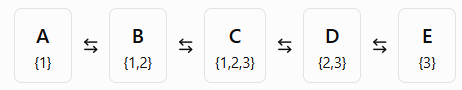

In [12]:

from collections import deque

variables = ["A", "B", "C", "D", "E"]

initial_domains = {
    "A": [1],
    "B": [1, 2],
    "C": [1, 2, 3],
    "D": [2, 3],
    "E": [3]
}

neighbors = {
    "A": ["B"],
    "B": ["A", "C"],
    "C": ["B", "D"],
    "D": ["C", "E"],
    "E": ["D"]
}


def compatible(x, vx, y, vy):
    return vx != vy


def revise(domains, x, y):
    revised = False

    for vx in domains[x][:]:
        if not any(compatible(x, vx, y, vy) for vy in domains[y]):
            domains[x].remove(vx)
            revised = True

    return revised


def ac3(domains, queue=None):
    if queue is None:
        queue = deque((x, y) for x in variables for y in neighbors[x])
    else:
        queue = deque(queue)

    while queue:
        x, y = queue.popleft()

        if revise(domains, x, y):
            if not domains[x]:
                return False
            for z in neighbors[x]:
                if z != y:
                    queue.append((z, x))

    return True


def consistent(x, value, assignment):
    return all(
        n not in assignment or compatible(x, value, n, assignment[n])
        for n in neighbors[x]
    )


attempts = {"basic": 0, "fc": 0, "mac": 0}


def backtrack_basic(assignment):
    if len(assignment) == len(variables):
        return assignment.copy()

    x = next(v for v in variables if v not in assignment)

    for value in initial_domains[x]:
        attempts["basic"] += 1

        if consistent(x, value, assignment):
            assignment[x] = value

            result = backtrack_basic(assignment)
            if result:
                return result

            del assignment[x]

    return None


def backtrack_fc(assignment, domains):
    if len(assignment) == len(variables):
        return assignment.copy()

    x = next(v for v in variables if v not in assignment)

    for value in domains[x]:
        attempts["fc"] += 1

        if not consistent(x, value, assignment):
            continue

        new_domains = {v: d[:] for v, d in domains.items()}
        new_domains[x] = [value]
        assignment[x] = value

        ok = True
        for n in neighbors[x]:
            if n not in assignment and value in new_domains[n]:
                new_domains[n].remove(value)
                if not new_domains[n]:
                    ok = False

        if ok:
            result = backtrack_fc(assignment, new_domains)
            if result:
                return result

        del assignment[x]

    return None


def backtrack_mac(assignment, domains):
    if len(assignment) == len(variables):
        return assignment.copy()

    x = next(v for v in variables if v not in assignment)

    for value in domains[x]:
        attempts["mac"] += 1

        if not consistent(x, value, assignment):
            continue

        new_domains = {v: d[:] for v, d in domains.items()}

        assignment[x] = value
        new_domains[x] = [value]

        queue = deque((n, x) for n in neighbors[x])

        if ac3(new_domains, queue):
            result = backtrack_mac(assignment, new_domains)
            if result:
                return result

        del assignment[x]

    return None


def fresh():
    return {v: initial_domains[v][:] for v in variables}


domains = fresh()
print("Initial domains:", domains)
print("AC-3 successful:", ac3(domains))
print("Domains after AC-3:", domains)

domains = fresh()
solution = backtrack_mac({}, domains)
print("MAC solution:", solution)

print()
print("Basic backtracking:", backtrack_basic({}))
print("Forward checking:", backtrack_fc({}, fresh()))
print("Candidate assignments attempted:", attempts)


Initial domains: {'A': [1], 'B': [1, 2], 'C': [1, 2, 3], 'D': [2, 3], 'E': [3]}
AC-3 successful: True
Domains after AC-3: {'A': [1], 'B': [2], 'C': [1, 3], 'D': [2], 'E': [3]}
MAC solution: {'A': 1, 'B': 2, 'C': 1, 'D': 2, 'E': 3}

Basic backtracking: {'A': 1, 'B': 2, 'C': 1, 'D': 2, 'E': 3}
Forward checking: {'A': 1, 'B': 2, 'C': 1, 'D': 2, 'E': 3}
Candidate assignments attempted: {'basic': 6, 'fc': 5, 'mac': 5}


**Analysis**

- **Why AC-3 rechecks arcs:** When a domain shrinks, values in neighbouring domains that depended on the removed value may lose their support, so the arcs pointing to that variable must be checked again.
- **Does AC-3 guarantee a solution?** No. It only guarantees every arc is consistent. A CSP can be arc-consistent and still have no solution (it only guarantees one when, for example, the graph is a tree).
- **MAC vs forward checking:** MAC propagates through the neighbours' neighbours and beyond, so it finds inconsistencies between two unassigned variables, which forward checking misses.
- **Cost:** After each assignment MAC runs AC-3 over many arcs and repeats them as domains change, whereas forward checking only looks at the direct neighbours of the assigned variable.

### Task 5: Network Configuration Using a Tree-Structured CSP

In [13]:
variables = ["A", "B", "C", "D", "E"]

domains = {
    "A": [1],
    "B": [1, 2],
    "C": [1, 2],
    "D": [2, 3],
    "E": [3]
}

parent = {
    "A": None, "B": "A", "C": "B",
    "D": "C", "E": "D"
}

edges = [(parent[v], v) for v in variables if parent[v]]
adjacent = {v: [] for v in variables}
for p, c in edges:
    adjacent[p].append(c)
    adjacent[c].append(p)

seen = {variables[0]}
stack = [variables[0]]
while stack:
    for n in adjacent[stack.pop()]:
        if n not in seen:
            seen.add(n)
            stack.append(n)

print("Connected:", len(seen) == len(variables))
print("Acyclic:", len(edges) == len(variables) - 1)
print("Order root to leaves:", variables)

removed_count = 0
failed = False

for child in reversed(variables[1:]):
    p = parent[child]

    for value in domains[p][:]:
        if not any(value != c for c in domains[child]):
            domains[p].remove(value)
            removed_count += 1

    if not domains[p]:
        failed = True
        print("Failure: domain of", p, "is empty")
        break

if not failed:
    config = {variables[0]: domains[variables[0]][0]}

    for v in variables[1:]:
        config[v] = next(x for x in domains[v] if x != config[parent[v]])

    print("Configuration:", config)
    print("All constraints satisfied:", all(config[parent[v]] != config[v] for v in variables[1:]))

print("Domain values removed:", removed_count)

Connected: True
Acyclic: True
Order root to leaves: ['A', 'B', 'C', 'D', 'E']
Configuration: {'A': 1, 'B': 2, 'C': 1, 'D': 2, 'E': 3}
All constraints satisfied: True
Domain values removed: 3


**Analysis**

- **Why reverse order first:** Pruning from the leaves up makes each parent value supported by its child. Then, going from the root down, every value picked has a compatible value for its child, so no backtracking is needed.
- **Why a tree:** In a tree each variable has exactly one parent, so one parent-child check is enough. In a graph with cycles, a value for one variable can depend on several others, and this method cannot guarantee a solution.
- **Versus backtracking:** Backtracking may try and undo many assignments (exponential in the worst case). The tree algorithm makes one backward pass and one forward pass, which is linear in the number of variables.

### Task 6: Crack the Secret Code: SEND + MORE = MONEY

**Part A: CSP formulation**

- **Variables:** S, E, N, D, M, O, R, Y.
- **Domains:** 0-9 for E, N, D, O, R, Y; 1-9 for S and M (leading letters).
- **All-different:** all eight letters must take different digits.
- **Equation:** SEND + MORE = MONEY must hold exactly, which restricts the digits column by column through carries.
- **Carries (C1..C4 are 0 or 1):**
  - Units: D + E = Y + 10*C1
  - Tens: N + R + C1 = E + 10*C2
  - Hundreds: E + O + C2 = N + 10*C3
  - Thousands: S + M + C3 = O + 10*C4
  - Ten-thousands: C4 = M

In [14]:
letters = ["S", "E", "N", "D", "M", "O", "R", "Y"]

assignment = {}
used_digits = set()
stats = {"attempts": 0}


def num(word):
    return int("".join(str(assignment[c]) for c in word))


def is_valid():
    return num("SEND") + num("MORE") == num("MONEY")


def backtrack(index, order, check):
    if index == len(order):
        return is_valid()

    letter = order[index]

    for digit in range(10):
        stats["attempts"] += 1

        if digit in used_digits:
            continue

        if digit == 0 and letter in "SM":
            continue

        assignment[letter] = digit
        used_digits.add(digit)

        if check() and backtrack(index + 1, order, check):
            return True

        del assignment[letter]
        used_digits.remove(digit)

    return False


def show():
    for letter in letters:
        print(letter, "=", assignment[letter])
    print(f"{num('SEND')} + {num('MORE')} = {num('MONEY')}")
    print("Candidate digit assignments attempted:", stats["attempts"])


print("Baseline")
print(backtrack(0, letters, lambda: True))
show()


def partial_valid():
    a = assignment
    carry = [0]
    for x, y, z in (("D", "E", "Y"), ("N", "R", "E"), ("E", "O", "N"), ("S", "M", "O")):
        if not all(k in a for k in (x, y, z)):
            return True
        c, r = divmod(a[x] + a[y] + carry[-1], 10)
        carry.append(c)
        if r != a[z]:
            return False
    return carry[4] == a["M"]


def carries():
    a = assignment
    c1, _ = divmod(a["D"] + a["E"], 10)
    c2, _ = divmod(a["N"] + a["R"] + c1, 10)
    c3, _ = divmod(a["E"] + a["O"] + c2, 10)
    c4, _ = divmod(a["S"] + a["M"] + c3, 10)
    return c1, c2, c3, c4


baseline_attempts = stats["attempts"]
assignment.clear()
used_digits.clear()
stats["attempts"] = 0

print()
print("Improved (early column checks)")
print(backtrack(0, ["D", "E", "Y", "N", "R", "O", "S", "M"], partial_valid))
show()
print("Carries C1..C4:", carries(), "| C4 == M:", carries()[3] == assignment["M"])
print("Baseline attempts:", baseline_attempts, "| Improved attempts:", stats["attempts"])

Baseline
True
S = 9
E = 5
N = 6
D = 7
M = 1
O = 0
R = 8
Y = 2
9567 + 1085 = 10652
Candidate digit assignments attempted: 6089936

Improved (early column checks)
True
S = 9
E = 5
N = 6
D = 7
M = 1
O = 0
R = 8
Y = 2
9567 + 1085 = 10652
Candidate digit assignments attempted: 12656
Carries C1..C4: (1, 1, 0, 1) | C4 == M: True
Baseline attempts: 6089936 | Improved attempts: 12656


**Analysis**

- **Uniqueness is not enough:** Many assignments have all-different digits but do not make SEND + MORE equal MONEY. The arithmetic equation must also hold.
- **Leading zeros:** S and M are leading digits of numbers, and a number does not start with 0. M also equals the final carry, which is 1.
- **Early column checks:** A column equation can be checked as soon as its digits are assigned, so a branch with a wrong column is cut immediately, instead of filling in the remaining letters. Here this reduced attempts from 6089936 to 12656.
- **Binary solver:** The equation involves many variables at once (an n-ary constraint) and arithmetic with carries, so it cannot be split into pairwise constraints between two variables.